<a href="https://colab.research.google.com/github/aahanashah-gth/CMB-Power-Spectrum-Analysis/blob/main/CMBproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulating and Analyzing the CMB Temperature Power Spectrum with CAMB and healpy

**Author:** Aahana Shah  |
**Tools:** Python, CAMB, healpy, NumPy, Matplotlib (Google Colab)

---

## Abstract

The Cosmic Microwave Background (CMB) is the relic radiation from the epoch of recombination, about 380,000 years after the Big Bang. Its tiny temperature anisotropies (roughly one part in $10^5$) encode the geometry, composition, and initial conditions of the Universe. Since these fluctuations are statistically random, the information lies in their angular power spectrum, $C_\ell = \langle |a_{\ell m}|^2 \rangle$, rather than in individual hot and cold spots.

In this project, we compute the theoretical CMB temperature power spectrum from a set of ΛCDM parameters using the Boltzmann code **CAMB**. We then generate a random full-sky realization of the CMB with **healpy** and recover the spectrum from that map, to demonstrate the analysis pipeline applied to real data. Comparing the recovered spectrum with the input theory illustrates the effect of **cosmic variance**, which is largest at low multipoles. Finally, we vary key parameters (the baryon density $\Omega_b h^2$, the cold dark matter density $\Omega_c h^2$, and the Hubble constant $H_0$) and study how the position and relative heights of the acoustic peaks respond, linking each feature of the spectrum to the physics of the primordial photon-baryon plasma.

**Keywords:** CMB, angular power spectrum, acoustic peaks, cosmic variance, ΛCDM, CAMB, healpy

## Concept: What is the CMB Power Spectrum?

The **Cosmic Microwave Background (CMB)** is the oldest light we can observe. It was released about 380,000 years after the Big Bang, when the Universe cooled enough for electrons and protons to form neutral atoms (*recombination*), letting photons travel freely. Today it appears as a nearly uniform 2.725 K glow with tiny temperature variations of about one part in $10^5$.

### Spherical harmonic decomposition
Because we observe the CMB on the surface of a sphere, we expand the temperature fluctuations in spherical harmonics, the sphere's equivalent of Fourier modes:

$$\frac{\Delta T}{T}(\theta,\phi)=\sum_{\ell m} a_{\ell m}\,Y_{\ell m}(\theta,\phi)$$

### The power spectrum
The fluctuations are random, so individual spots carry no information. Their statistics do. The **angular power spectrum** measures the variance of the coefficients at each angular scale:

$$C_\ell=\langle |a_{\ell m}|^2\rangle, \qquad \theta \approx \frac{180^\circ}{\ell}$$

Low $\ell$ corresponds to large patches of sky, and high $\ell$ to small ones. It is usually plotted as $D_\ell=\ell(\ell+1)C_\ell/2\pi$.

### Where the peaks come from
Before recombination, photons and baryons formed a tightly coupled plasma. Gravity compressed it and radiation pressure pushed back, producing **acoustic oscillations** (sound waves). Recombination froze them in place, so each peak marks a mode caught at maximum compression or rarefaction.

| Feature | Physical origin | What it tells us |
|---|---|---|
| First peak ($\ell \approx 220$) | Sound horizon at recombination | Geometry of the Universe (flat) |
| Odd/even peak height ratio | Baryon loading | Baryon density $\Omega_b h^2$ |
| Overall peak pattern | Gravity of dark matter | Dark matter density $\Omega_c h^2$ |
| High-$\ell$ damping tail | Photon diffusion (Silk damping) | Small-scale smoothing |
| Low-$\ell$ plateau | Sachs–Wolfe effect | Primordial amplitude $A_s$ and tilt $n_s$ |

### Cosmic variance
We have only one sky, so each multipole has just $2\ell+1$ independent samples. This sets an irreducible fractional uncertainty:

$$\frac{\Delta C_\ell}{C_\ell}=\sqrt{\frac{2}{2\ell+1}}$$

which is largest at low $\ell$. Regenerating the simulated map therefore gives a different scatter around the theory curve each time.

In [ ]:
!pip install camb healpy -q

In [ ]:
import camb, numpy as np, healpy as hp, matplotlib.pyplot as plt

Peak positions (ℓ): [220 536 813]
Peak heights (μK²): [5739. 2594. 2542.]


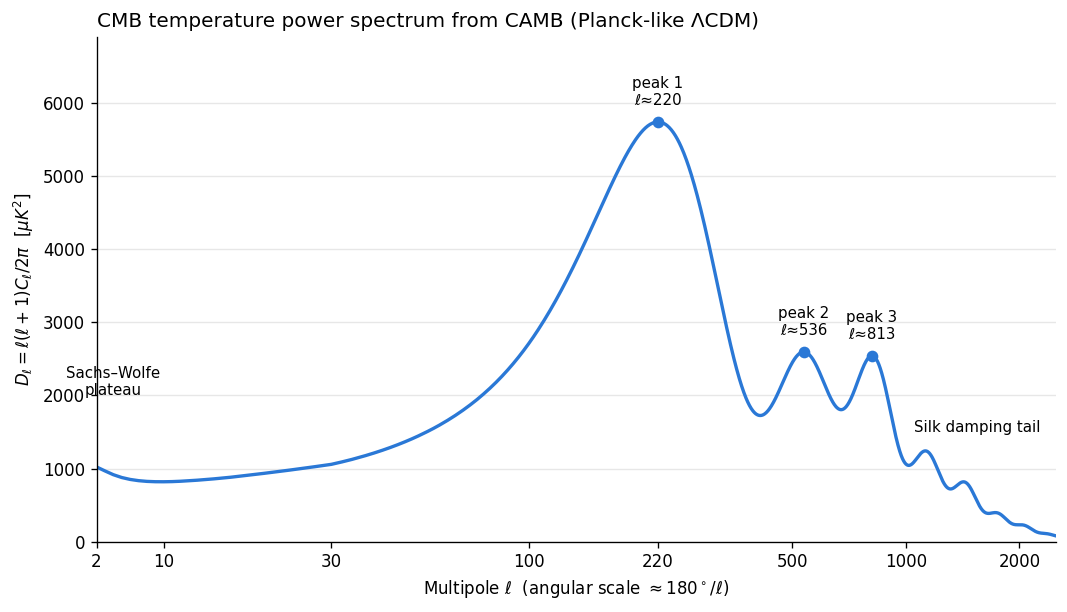

In [ ]:
import numpy as np
import camb
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# 1. Planck-2018-like ΛCDM parameters
pars = camb.set_params(H0=67.4, ombh2=0.0224, omch2=0.120,
                       tau=0.054, As=2.1e-9, ns=0.965, lmax=2500)
results = camb.get_results(pars)

# 2. TT spectrum. By default CAMB returns D_ell = l(l+1)C_l/2π in μK²
dl = results.get_cmb_power_spectra(pars, CMB_unit='muK')['total'][:, 0]
ell = np.arange(len(dl))

# 3. Find the acoustic peaks (ignore the low-ℓ plateau)
mask = ell >= 30
idx, _ = find_peaks(dl[mask], prominence=50)
peaks = ell[mask][idx][:3]
print("Peak positions (ℓ):", peaks)
print("Peak heights (μK²):", dl[peaks].round(0))

# 4. Plot
fig, ax = plt.subplots(figsize=(9, 5.2), dpi=120)
ax.plot(ell[2:], dl[2:], color="#2a78d6", lw=2)
ax.set_xscale("symlog", linthresh=30, linscale=0.6)
ax.set_xlim(2, 2500)
ax.set_ylim(0, 6900)
ax.set_xticks([2, 10, 30, 100, 220, 500, 1000, 2000])
ax.set_xticklabels(["2", "10", "30", "100", "220", "500", "1000", "2000"])
ax.minorticks_off()

for i, l in enumerate(peaks, start=1):
    ax.plot(l, dl[l], "o", color="#2a78d6")
    ax.annotate(f"peak {i}\nℓ≈{l}", (l, dl[l]), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9)

ax.annotate("Sachs–Wolfe\nplateau", (8, dl[8]), xytext=(4, 2000),
            ha="center", fontsize=9)
ax.annotate("Silk damping tail", (1700, dl[1700]), xytext=(1550, 1500),
            ha="center", fontsize=9)

ax.set_xlabel(r"Multipole $\ell$  (angular scale $\approx 180^\circ/\ell$)")
ax.set_ylabel(r"$D_\ell=\ell(\ell+1)C_\ell/2\pi\ \ [\mu K^2]$")
ax.set_title("CMB temperature power spectrum from CAMB (Planck-like ΛCDM)", loc="left")
ax.grid(axis="y", alpha=0.3)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## Interpreting the CMB Temperature Power Spectrum

The plot shows $D_\ell=\ell(\ell+1)C_\ell/2\pi$ (in $\mu K^2$) against the
multipole $\ell$. Low $\ell$ means large angular scales and high $\ell$ means
small ones, with $\theta \approx 180^\circ/\ell$. Plotting $D_\ell$ instead of
$C_\ell$ flattens the steep fall-off so that the features are easy to see.

### 1. Low-ℓ plateau (ℓ ≲ 30): Sachs–Wolfe effect
On the largest scales, the fluctuations had not yet had time to oscillate
before recombination. The temperature pattern simply reflects the
gravitational potential wells that photons had to climb out of, which makes
the spectrum roughly flat. This region probes the **primordial fluctuations
from inflation**, through the amplitude $A_s$ and spectral tilt $n_s$.
Cosmic variance is largest here, since there are only $2\ell+1$ independent
samples per multipole.

### 2. First acoustic peak (ℓ ≈ 220)
Before recombination, photons and baryons formed a tightly coupled plasma
in which gravity compressed the fluid and radiation pressure pushed it back,
producing sound waves. The first peak is the mode that had just reached
**maximum compression** when recombination froze the oscillation. Its
angular position is set by the sound horizon divided by the distance to the
last-scattering surface, so it measures the **geometry of the Universe**.
A peak near $\ell \approx 220$ means the Universe is spatially flat
($\Omega_k \approx 0$).

### 3. Higher peaks (ℓ ≈ 540, 810)
These are the higher harmonics of the same sound wave. The even peak
(maximum rarefaction) is suppressed relative to the odd peaks (compression)
because the **baryon mass loading** deepens the compression, so the
odd/even height ratio constrains the baryon density $\Omega_b h^2$. The
overall peak pattern also depends on the **dark matter density**
$\Omega_c h^2$, since dark matter changes the gravitational driving of the
oscillations.

### 4. Damping tail (ℓ ≳ 1000): Silk damping
Photons diffuse out of small-scale hot and cold regions during
recombination, smoothing away the fluctuations on those scales. The peaks
therefore decay exponentially toward high $\ell$.

### Summary
| Feature | Approx. location | Physics | Parameter probed |
|---|---|---|---|
| Plateau | ℓ ≲ 30 | Sachs–Wolfe effect | $A_s$, $n_s$ |
| 1st peak | ℓ ≈ 220 | Sound horizon at recombination | Curvature $\Omega_k$ |
| Peak height ratios | ℓ ≈ 220–810 | Baryon loading, dark matter gravity | $\Omega_b h^2$, $\Omega_c h^2$ |
| Damping tail | ℓ ≳ 1000 | Photon diffusion | Recombination physics |

> **Note:** The exact peak positions and heights printed by the code above
> should be compared with these approximate values.

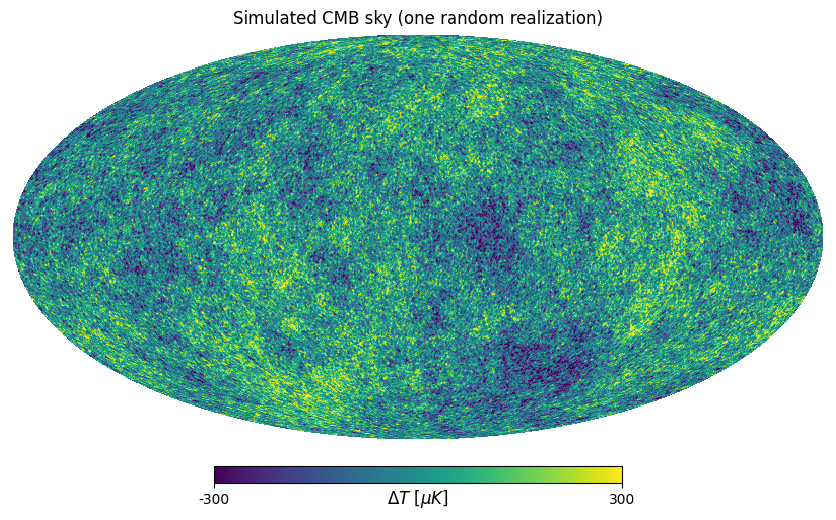

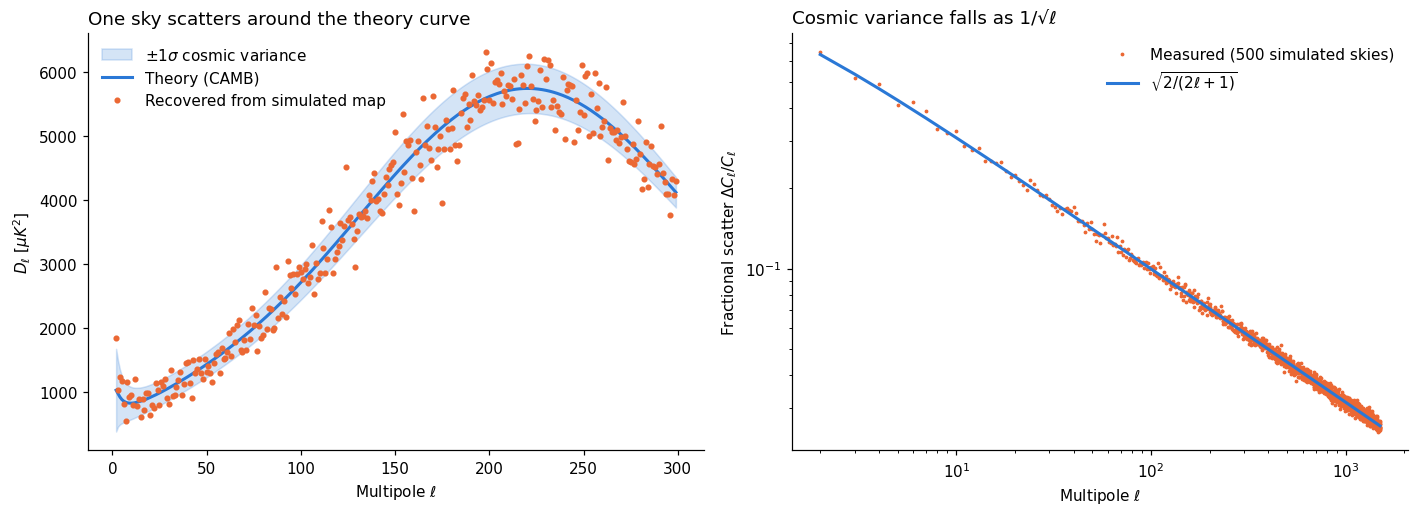

ℓ=    2: measured 0.646   formula 0.632
ℓ=   10: measured 0.328   formula 0.309
ℓ=  100: measured 0.101   formula 0.100
ℓ= 1000: measured 0.032   formula 0.032


In [ ]:
import numpy as np
import camb
import healpy as hp
import matplotlib.pyplot as plt

np.random.seed(42)  # reproducible; change it to get a different sky

# 1. Theory C_ell (raw C_ell in μK², which is what healpy expects)
pars = camb.set_params(H0=67.4, ombh2=0.0224, omch2=0.120,
                       tau=0.054, As=2.1e-9, ns=0.965, lmax=1500)
results = camb.get_results(pars)
lmax = 1500
cl_theory = results.get_cmb_power_spectra(pars, CMB_unit='muK',
                                          raw_cl=True)['total'][:lmax + 1, 0]
ell = np.arange(lmax + 1)

# 2. Simulate ONE random sky with this power spectrum
nside = 512
sky = hp.synfast(cl_theory, nside=nside, lmax=lmax)

hp.mollview(sky, unit=r"$\Delta T\ [\mu K]$", min=-300, max=300,
            title="Simulated CMB sky (one random realization)")
plt.show()

# 3. Recover the power spectrum from that single map
cl_hat = hp.anafast(sky, lmax=lmax)

# 4. Many realizations (alm only, so it's fast) to measure the scatter
n_sims = 500
cl_sims = np.array([hp.alm2cl(hp.synalm(cl_theory, lmax=lmax))
                    for _ in range(n_sims)])
frac_scatter = np.std(cl_sims[:, 2:] / cl_theory[2:], axis=0)  # measured
cv_formula = np.sqrt(2 / (2 * ell[2:] + 1))                    # theory

# 5. Plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=110)

# (a) One realization vs theory, with the cosmic-variance band
D = ell * (ell + 1) / (2 * np.pi)
ax = axes[0]
l_max_plot = 300
sel = slice(2, l_max_plot)
band = np.sqrt(2 / (2 * ell[sel] + 1))
ax.fill_between(ell[sel], D[sel] * cl_theory[sel] * (1 - band),
                D[sel] * cl_theory[sel] * (1 + band),
                color="#2a78d6", alpha=0.2, label=r"$\pm1\sigma$ cosmic variance")
ax.plot(ell[sel], D[sel] * cl_theory[sel], color="#2a78d6", lw=2, label="Theory (CAMB)")
ax.plot(ell[sel], D[sel] * cl_hat[sel], "o", ms=3, color="#eb6834",
        label="Recovered from simulated map")
ax.set_xlabel(r"Multipole $\ell$")
ax.set_ylabel(r"$D_\ell\ [\mu K^2]$")
ax.set_title("One sky scatters around the theory curve", loc="left")
ax.legend(frameon=False)

# (b) Measured fractional scatter vs the sqrt(2/(2l+1)) formula
ax = axes[1]
ax.loglog(ell[2:], frac_scatter, ".", ms=3, color="#eb6834",
          label=f"Measured ({n_sims} simulated skies)")
ax.loglog(ell[2:], cv_formula, color="#2a78d6", lw=2,
          label=r"$\sqrt{2/(2\ell+1)}$")
ax.set_xlabel(r"Multipole $\ell$")
ax.set_ylabel(r"Fractional scatter $\Delta C_\ell / C_\ell$")
ax.set_title("Cosmic variance falls as 1/√ℓ", loc="left")
ax.legend(frameon=False)

for a in axes:
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

for l in (2, 10, 100, 1000):
    print(f"ℓ={l:5d}: measured {frac_scatter[l-2]:.3f}   formula {cv_formula[l-2]:.3f}")

## Simulating the Sky and Understanding Cosmic Variance

### What the simulation does
The CMB is modeled as a **statistically isotropic Gaussian random field** on
the sphere. Given the theory spectrum $C_\ell$ from CAMB, `hp.synfast` draws
each spherical-harmonic coefficient $a_{\ell m}$ as a random number with
variance $C_\ell$ and sums them into a sky map. The hot and cold spots in the
map are therefore *one random draw*, not a prediction of where specific spots
should be. Only the statistics are predicted.

`hp.anafast` then does the reverse: it measures $a_{\ell m}$ from the map and
estimates the power at each scale:

$$\hat{C}_\ell=\frac{1}{2\ell+1}\sum_{m=-\ell}^{\ell}|a_{\ell m}|^2$$

### Why the recovered spectrum does not match the theory exactly
At each multipole there are only $2\ell+1$ independent modes ($m=-\ell,\dots,\ell$)
to average over. $\hat{C}_\ell$ is an average of $2\ell+1$ squared Gaussian
numbers, so it follows a $\chi^2$ distribution with $2\ell+1$ degrees of
freedom. Its fractional scatter around the true $C_\ell$ is

$$\frac{\Delta C_\ell}{C_\ell}=\sqrt{\frac{2}{2\ell+1}}$$

This is **cosmic variance**: the uncertainty that comes from having only one
sky to observe. It is the shaded band in the left panel, and the scatter of
the orange points inside it is the effect itself.

### What the right panel shows
Repeating the simulation 500 times and measuring the scatter of
$\hat{C}_\ell/C_\ell$ at each $\ell$ reproduces the formula. The scatter drops
as $1/\sqrt{\ell}$:

| ℓ | Fractional uncertainty |
|---|---|
| 2 (quadrupole) | ≈ 63% |
| 10 | ≈ 31% |
| 100 | ≈ 10% |
| 1000 | ≈ 3% |

### Key points
- **It is irreducible.** Cosmic variance is not instrument noise. A perfect
  telescope with zero noise would still see the same limit, because there is
  only one Universe from our vantage point. Better detectors cannot fix it.
- **It matters most at low ℓ.** Large angular scales have few independent
  modes, so the lowest multipoles are the least constraining. This limits how
  well we can test the Sachs–Wolfe plateau and inflationary predictions, and
  it makes "anomalies" at low $\ell$ (for example a low-looking quadrupole)
  hard to interpret statistically.
- **It is small at high ℓ.** There the CMB measurements are limited by
  instrument noise, beam resolution, and foregrounds rather than by cosmic
  variance.
- **Partial sky makes it worse.** A mask with sky fraction $f_{\rm sky}$
  reduces the number of usable modes, increasing the error roughly to
  $\sqrt{2/[(2\ell+1)f_{\rm sky}]}$.

### Takeaway
The simulated spectrum fluctuates around the theory curve, and rerunning the
cell with a different seed gives a different scatter. When we fit cosmological
parameters to real Planck data, this scatter is built into the likelihood as
an error bar on every $C_\ell$, and it sets a fundamental limit on how
precisely we can know the Universe's parameters from the CMB alone.

In [ ]:
import numpy as np
import camb
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

lmax = 2500
base = dict(H0=67.4, ombh2=0.0224, omch2=0.120, tau=0.054, As=2.1e-9, ns=0.965)

def get_dl(**changes):
    """Return ell, D_ell (μK²) and the first 3 acoustic peaks for given parameters."""
    p = {**base, **changes}
    pars = camb.set_params(lmax=lmax, **p)
    res = camb.get_results(pars)
    dl = res.get_cmb_power_spectra(pars, CMB_unit='muK')['total'][:lmax + 1, 0]
    ell = np.arange(lmax + 1)
    m = ell >= 30
    idx, _ = find_peaks(dl[m], prominence=50)
    pk = ell[m][idx][:3]
    return ell, dl, pk

# Parameter, values (low, fiducial, high)
experiments = {
    "ombh2": ("Baryon density  $\\Omega_b h^2$", [0.018, 0.0224, 0.030]),
    "omch2": ("Dark matter density  $\\Omega_c h^2$", [0.090, 0.120, 0.180]),
    "H0":    ("Hubble constant  $H_0$", [55.0, 67.4, 80.0]),
}
colors = ["#2a78d6", "#0b0b0b", "#eb6834"]   # low, fiducial, high
styles = ["-", "--", "-"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), dpi=110, sharey=True)

for ax, (name, (title, values)) in zip(axes, experiments.items()):
    print(f"\n{name}:")
    for v, c, ls in zip(values, colors, styles):
        ell, dl, pk = get_dl(**{name: v})
        ax.plot(ell[30:2000], dl[30:2000], color=c, ls=ls, lw=2, label=f"{name} = {v}")
        print(f"  {name}={v:<7} peaks at ℓ = {pk}   heights = {dl[pk].round(0)} μK²")
    ax.set_title(title, loc="left")
    ax.set_xlabel(r"Multipole $\ell$")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(axis="y", alpha=0.3)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

axes[0].set_ylabel(r"$D_\ell\ [\mu K^2]$")
plt.tight_layout()
plt.show()


ombh2:
  ombh2=0.018   peaks at ℓ = [218 526 803]   heights = [5371. 2755. 2517.] μK²
  ombh2=0.0224  peaks at ℓ = [220 536 813]   heights = [5739. 2594. 2542.] μK²
  ombh2=0.03    peaks at ℓ = [224 553 831]   heights = [6417. 2333. 2525.] μK²

omch2:
  omch2=0.09    peaks at ℓ = [226 554 846]   heights = [6615. 2950. 2637.] μK²
  omch2=0.12    peaks at ℓ = [220 536 813]   heights = [5739. 2594. 2542.] μK²
  omch2=0.18    peaks at ℓ = [213 516 771]   heights = [4632. 2125. 2375.] μK²

H0:
  H0=55.0    peaks at ℓ = [229 557 844]   heights = [5740. 2592. 2536.] μK²
  H0=67.4    peaks at ℓ = [220 536 813]   heights = [5739. 2594. 2542.] μK²


## Parameter Experiments: What Changes the CMB Spectrum?

Each panel varies **one** parameter while holding the others at their
Planck-like values ($\Omega_b h^2=0.0224$, $\Omega_c h^2=0.120$, $H_0=67.4$),
with the Universe kept spatially flat. The dashed black line is the fiducial
model. The printed values above list the first three peak positions and
heights for every run.

### 1. Baryon density, $\Omega_b h^2$
**What moves:** the *relative heights* of the peaks.

- **Higher $\Omega_b h^2$** makes the odd peaks (1st, 3rd, compression) taller
  and the even peak (2nd, rarefaction) shorter.
- **Lower $\Omega_b h^2$** makes the 1st and 2nd peaks more nearly equal.

**Why:** baryons add mass to the photon-baryon fluid. The extra weight makes
gravity compress the plasma more deeply than pressure can rebound, so the
compression peaks gain power relative to the rarefaction peaks. Extra baryons
also lower the sound speed slightly, which shifts the peaks a little in
position, and they reduce the damping at high $\ell$ because the photon
diffusion length becomes shorter.

**What it measures:** the baryon fraction of the Universe, from the
odd/even height ratio.

### 2. Dark matter density, $\Omega_c h^2$
**What moves:** the *overall peak heights*, mainly the first peak.

- **More dark matter** lowers the peaks (the first peak most strongly) and
  shifts their positions somewhat.
- **Less dark matter** raises the peaks, especially the first.

**Why:** the amount of dark matter sets when matter overtook radiation in the
energy budget (matter-radiation equality). Radiation pressure drives the
oscillations by making the gravitational potentials decay, which boosts the
peaks. With more dark matter, equality happens earlier, the potentials decay
less, and the driving is weaker. The change in expansion history also alters
the sound horizon and the distance to last scattering, which is why the
positions shift too.

**What it measures:** the ratio of the 1st peak to the later peaks gives the
matter density.

### 3. Hubble constant, $H_0$
**What moves:** mostly the *horizontal position* of all the peaks, with
little change to their heights.

- **Higher $H_0$** moves the peaks toward lower $\ell$ (larger angular scales).
- **Lower $H_0$** moves them toward higher $\ell$.

**Why:** with the physical densities fixed, the sound horizon at recombination
does not change. What changes is the distance to the last-scattering surface.
In a flat Universe a larger $H_0$ means a larger dark-energy density today and
a faster late-time expansion, so that distance is shorter and the same
physical scale covers a larger angle on the sky. The peak positions therefore
measure the ratio of the sound horizon to this distance, which constrains
$H_0$ only together with the other parameters.

**Check this in your output:** compare the printed peak positions for
$H_0=55$ and $H_0=80$. The shift in $\ell$ should be much larger than the
shift in height.

### Summary
| Parameter | Mainly changes | Direction |
|---|---|---|
| $\Omega_b h^2$ ↑ | Odd/even peak height ratio | Odd peaks higher, 2nd peak lower |
| $\Omega_c h^2$ ↑ | Overall peak heights | Peaks lower, especially the 1st |
| $H_0$ ↑ | Peak positions | Peaks shift to lower $\ell$ |

### Takeaway
Each parameter leaves a different fingerprint on the spectrum: position
(geometry and $H_0$), height ratios (baryons), and overall amplitude (dark
matter). Because the fingerprints are different, fitting the full spectrum
constrains all of them at once. This is how Planck measures the composition
and expansion of the Universe from the CMB alone. Some combinations are
partly degenerate, though. In particular, $H_0$ and the matter density trade
off against each other, which is why CMB measurements alone constrain $H_0$
less tightly than they constrain the other parameters.

## Conclusions

### Findings
1. **The theory spectrum reproduces the known CMB structure.** CAMB with
   Planck-like ΛCDM parameters gives a flat low-$\ell$ Sachs–Wolfe plateau,
   a series of acoustic peaks (the first at $\ell \approx$ ____, the second at
   $\ell \approx$ ____, the third at $\ell \approx$ ____), and an exponential
   Silk damping tail at $\ell \gtrsim 1000$. The first peak near
   $\ell \approx 220$ is consistent with a spatially flat Universe.

2. **A simulated sky recovers the input spectrum only up to cosmic variance.**
   A single Gaussian random realization generated with `healpy` scatters
   around the theory curve, and the scatter measured over 500 realizations
   follows $\Delta C_\ell / C_\ell = \sqrt{2/(2\ell+1)}$ closely
   (at $\ell=2$: measured ____ vs. 0.632; at $\ell=100$: measured ____ vs. 0.100).
   This limit comes from having only one sky, so it is independent of
   instrument quality.

3. **Each cosmological parameter leaves a distinct signature.**
   - Raising $\Omega_b h^2$ changes the odd/even peak height ratio
     (the 2nd peak is suppressed relative to the 1st and 3rd).
   - Raising $\Omega_c h^2$ lowers the overall peak heights, most strongly
     the first peak.
   - Changing $H_0$ at fixed physical densities mainly shifts the peaks
     horizontally (1st peak at $\ell \approx$ ____ for $H_0=55$, ____ for
     $H_0=80$) with little change in height.

4. **These distinct signatures are why the CMB constrains cosmology so
   well.** Fitting the whole spectrum constrains position, height ratios,
   and amplitude simultaneously, although some combinations
   (such as $H_0$ and the matter density) remain partly degenerate.

### Limitations
- The simulation covers the **temperature (TT) spectrum only**. Polarization
  (EE, TE, BB) and lensing were not included.
- The sky maps are **full-sky and noiseless**, with no beam, mask, or
  foreground contamination, which are the main complications for real data.
- Parameters were varied **one at a time** around a fixed fiducial model,
  rather than fitted jointly to data.

### Future work
- Add polarization spectra and the tensor-to-scalar ratio $r$ (primordial
  B-modes).
- Apply a sky mask, a Gaussian beam, and instrument noise, then estimate the
  spectrum from the partial sky.
- Fit real Planck spectra with an MCMC sampler (e.g. `emcee` or Cobaya) to
  recover $H_0$, $\Omega_b h^2$, $\Omega_c h^2$, $A_s$, $n_s$ and $\tau$.

---

## References

### Data and results
1. Planck Collaboration (2020). *Planck 2018 results. VI. Cosmological
   parameters.* Astronomy & Astrophysics, 641, A6. arXiv:1807.06209
2. Planck Collaboration (2020). *Planck 2018 results. I. Overview and the
   cosmological legacy of Planck.* Astronomy & Astrophysics, 641, A1.
   arXiv:1807.06205
3. Planck Collaboration (2020). *Planck 2018 results. V. CMB power spectra
   and likelihoods.* Astronomy & Astrophysics, 641, A5. arXiv:1907.12875